NOTE:BASE_CNN_ORGINAL AND MOBILENET_BINARY were removed later

In [ ]:
# Colab essentials
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# TensorFlow
import tensorflow as tf
from tensorflow.keras.models import load_model

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Feature-space novelty
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

print("TensorFlow:", tf.__version__)


TensorFlow: 2.19.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


ValueError: mount failed

In [ ]:
import os

os.listdir('/content/drive/MyDrive')


['IMG-20240708-WA0001.jpg',
 'Classroom',
 'PRACT 4.docx',
 'Screenshot (8).png',
 'impact-of-internet-of-things-on-society-IJERTCONV5IS03020.pdf',
 'IMG-20241010-WA0035.jpg',
 'rakshit_ladda.pdf',
 'SAMEEKSHA-IOT (2).pptx',
 'SAMEEKSHA-IOT (1).pptx',
 'SAMEEKSHA-IOT.pptx',
 'Copy of ELECTRICALAPPROVAL.gdoc',
 'Screenshot 2024-11-08 113926.png',
 'eee assingment.pdf',
 'Document from Rakshit Ladda.pdf',
 'BT24ECE063. RAKSHIT LADDA.pdf',
 'SAMKEESHA IOT funal paper.pdf',
 'Screenshot_2025-01-19-21-04-30-312_com.phonepe.app.jpg',
 'Screenshot_2025-01-25-10-17-57-042_com.miui.gallery.jpg',
 'Screenshot_2025-04-19-16-14-39-959_com.phonepe.app.jpg',
 'Untitled spreadsheet.gsheet',
 'Colab Notebooks',
 'RAKSHIT_LADDA(BT24CSD066).png',
 'BT24CSD066(RAKSHIT LADDA).png',
 'RAKSHIT LADDA(BT24CSD066) LOGO.jpg',
 ' BRANCH_CHANGE_APPLICATION.gdoc',
 'BT24CSD066(RAKSHIT LADDA)MINDEASE.pdf',
 'Screenshot 2025-09-05 121312.png',
 'TF_2025_BROCHURE EVE1.pdf',
 '50_Startups (1).csv.gsheet',
 '50_Startup

In [ ]:
MODEL_PATHS = {
    "BaseCNN_Original": "/content/drive/MyDrive/FIXED_MODELS/base_cnn_original.keras",
    "BaseCNN_Augmented": "/content/drive/MyDrive/FIXED_MODELS/base_cnn_augmented.keras",
    "MobileNet_Binary": "/content/drive/MyDrive/FIXED_MODELS/mobilenet_binary.keras",
    "ResNet_Binary": "/content/drive/MyDrive/resnet50_mendeley_best.h5",
    "MobileNet_16_Frozen": "/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras",
    "MobileNet_16_Finetuned": "/content/drive/MyDrive/MobileNetV2_16Class_Final/mobilenetv2_16class_best.keras",
    "Fusion_Model": "/content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras"
}


In [ ]:
models = {}
for name, path in MODEL_PATHS.items():
    models[name] = load_model(path, compile=False)
    print(f"Loaded: {name}")


Loaded: BaseCNN_Original
Loaded: BaseCNN_Augmented
Loaded: MobileNet_Binary
Loaded: ResNet_Binary
Loaded: MobileNet_16_Frozen
Loaded: MobileNet_16_Finetuned
Loaded: Fusion_Model


In [ ]:
BINARY_LABELS = ["Fresh", "Rotten"]

MULTICLASS_LABELS = [
    "FreshApple", "FreshBanana", "FreshGrape", "FreshGuava",
    "FreshJujube", "FreshOrange", "FreshPomegranate", "FreshStrawberry",
    "RottenApple", "RottenBanana", "RottenGrape", "RottenGuava",
    "RottenJujube", "RottenOrange", "RottenPomegranate", "RottenStrawberry"
]


In [ ]:
IMG_SIZE = 224

def preprocess_image(img_path):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
    img = tf.keras.preprocessing.image.img_to_array(img)
    img = img / 255.0
    return np.expand_dims(img, axis=0)


In [ ]:
def load_dataset(dataset_dir):
    image_paths, labels = [], []
    for class_name in os.listdir(dataset_dir):
        class_dir = os.path.join(dataset_dir, class_name)
        if not os.path.isdir(class_dir):
            continue
        for img in os.listdir(class_dir):
            image_paths.append(os.path.join(class_dir, img))
            labels.append(class_name)
    return image_paths, labels


In [ ]:
def predict_model(model, img_path):
    img = preprocess_image(img_path)
    probs = model.predict(img, verbose=0)[0]
    pred_idx = np.argmax(probs)
    return pred_idx, probs


In [ ]:
def evaluate_model(model, img_paths, true_labels, class_names):
    y_true, y_pred = [], []

    for img, label in zip(img_paths, true_labels):
        pred_idx, _ = predict_model(model, img)
        y_true.append(class_names.index(label))
        y_pred.append(pred_idx)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro"),
        "recall": recall_score(y_true, y_pred, average="macro"),
        "f1": f1_score(y_true, y_pred, average="macro"),
        "report": classification_report(y_true, y_pred, target_names=class_names)
    }


In [ ]:
def spoilage_stage(prob):
    if prob >= 0.9:
        return "Clearly Fresh/Rotten"
    elif prob >= 0.6:
        return "Early Spoilage (Transitional)"
    else:
        return "Highly Uncertain"


In [ ]:
def extract_features(model, img_path):
    feature_extractor = tf.keras.Model(
        inputs=model.input,
        outputs=model.layers[-2].output
    )
    img = preprocess_image(img_path)
    return feature_extractor.predict(img, verbose=0)[0]


In [ ]:
def plot_feature_space(features, labels):
    features = StandardScaler().fit_transform(features)
    pca = PCA(n_components=2)
    reduced = pca.fit_transform(features)

    plt.figure(figsize=(6,6))
    sns.scatterplot(x=reduced[:,0], y=reduced[:,1], hue=labels)
    plt.title("Feature Space (Fresh ↔ Rotten)")
    plt.show()


In [ ]:
DATASET_PATHS = {
    "FreshRotten_Sriramr": "/content/kaggle_fruits",          # fruits-fresh-and-rotten-for-classification
    "FruitMate": "/content/fruitmate",
    "FruitQuality": "/content/fruit_quality",
    "FreshOrRotten_Amit": "/content/fresh_rotten_external"
}


In [ ]:
import os

path_to_verify = '/content/drive/MyDrive/TestDatasets/Mendeley'

if os.path.exists(path_to_verify):
    if os.path.isdir(path_to_verify):
        print(f"The path '{path_to_verify}' exists and is a directory.")
    else:
        print(f"The path '{path_to_verify}' exists but is not a directory (it might be a file).")
else:
    print(f"The path '{path_to_verify}' does not exist.")

The path '/content/drive/MyDrive/TestDatasets/Mendeley' does not exist.


In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
!kaggle datasets download -d sriramr/fruits-fresh-and-rotten-for-classification


Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [01:56<00:00, 226MB/s]
100% 3.58G/3.58G [01:56<00:00, 33.0MB/s]


In [ ]:
!unzip fruits-fresh-and-rotten-for-classification.zip -d /content/kaggle_fruits


Streaming output truncated to the last 5000 lines.
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.09 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.18 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.24 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.37 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.02.51 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.02 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.12 PM.png  
  inflating: /content/kaggle_fruits/dataset/train/rottenapples/rotated_by_60_Screen Shot 2018-06-07 at 3.03.2

In [ ]:
!kaggle datasets download -d riescoalieffe/fruitmate



Dataset URL: https://www.kaggle.com/datasets/riescoalieffe/fruitmate
License(s): unknown
  0% 0.00/12.6M [00:00<?, ?B/s]
100% 12.6M/12.6M [00:00<00:00, 1.19GB/s]


In [ ]:
!unzip fruitmate.zip -d /content/fruitmate


Archive:  fruitmate.zip
  inflating: /content/fruitmate/Testing/Overripe/Overripe004.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe006.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe007.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe008.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe011.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe012.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe021.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe022.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe023.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe027.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe028.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe029.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe036.jpeg  
  inflating: /content/fruitmate/Testing/Overripe/Overripe038.jpeg  
  inflating: /content/fr

In [ ]:
# Download Fruits Quality (Fresh vs Rotten)
!kaggle datasets download -d nourabdoun/fruits-quality-fresh-vs-rotten


Dataset URL: https://www.kaggle.com/datasets/nourabdoun/fruits-quality-fresh-vs-rotten
License(s): other
  0% 0.00/11.2M [00:00<?, ?B/s]
100% 11.2M/11.2M [00:00<00:00, 818MB/s]


In [ ]:
# Unzip dataset
!unzip -q fruits-quality-fresh-vs-rotten.zip -d /content/fruit_quality


In [ ]:
!unzip "/content/drive/MyDrive/Original Image -2.zip" -d "/content/fruitvision_raw"


unzip:  cannot find or open /content/drive/MyDrive/Original Image -2.zip, /content/drive/MyDrive/Original Image -2.zip.zip or /content/drive/MyDrive/Original Image -2.zip.ZIP.


In [ ]:
!kaggle datasets download -d amitsubhashagrahari/fresh-or-rotten-fruit


Dataset URL: https://www.kaggle.com/datasets/amitsubhashagrahari/fresh-or-rotten-fruit
License(s): apache-2.0
  0% 0.00/1.75M [00:00<?, ?B/s]
100% 1.75M/1.75M [00:00<00:00, 558MB/s]


In [ ]:
!unzip fresh-or-rotten-fruit.zip -d /content/fresh_rotten_external


Archive:  fresh-or-rotten-fruit.zip
  inflating: /content/fresh_rotten_external/Dataset_1/1.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/10.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/100.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/101.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/102.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/103.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/104.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/105.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/106.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/107.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/108.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/109.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/11.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/110.jpeg  
  inflating: /content/fresh_rotten_external/Dataset_1/111.

In [ ]:
import os

os.listdir('/content')


['.config',
 'fresh-or-rotten-fruit.zip',
 'fruits-quality-fresh-vs-rotten.zip',
 'fruits-fresh-and-rotten-for-classification.zip',
 'fruitmate',
 'fresh_rotten_external',
 'fruit_quality',
 'kaggle_fruits',
 'drive',
 'fruitmate.zip',
 'sample_data']

In [ ]:
import os

for name, path in DATASET_PATHS.items():
    print(f"{name}: {os.path.exists(path)}")


FreshRotten_Sriramr: True
FruitMate: True
FruitQuality: True
FreshOrRotten_Amit: True


In [ ]:
def count_images(root):
    count = 0
    for r, d, f in os.walk(root):
        count += len([x for x in f if x.lower().endswith(('.jpg','.png','.jpeg'))])
    return count

for name, path in DATASET_PATHS.items():
    print(f"{name}: {count_images(path)} images")


FreshRotten_Sriramr: 27198 images
FruitMate: 563 images
FruitQuality: 359 images
FreshOrRotten_Amit: 230 images


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
BINARY_LABELS = ['Fresh', 'Rotten']

MULTICLASS_LABELS = [
    'FreshApple','FreshBanana','FreshGrape','FreshGuava',
    'FreshJujube','FreshOrange','FreshPomegranate','FreshStrawberry',
    'RottenApple','RottenBanana','RottenGrape','RottenGuava',
    'RottenJujube','RottenOrange','RottenPomegranate','RottenStrawberry'
]

FRESH_IDX = [i for i,l in enumerate(MULTICLASS_LABELS) if l.startswith('Fresh')]
ROTTEN_IDX = [i for i,l in enumerate(MULTICLASS_LABELS) if l.startswith('Rotten')]


In [ ]:
MODEL_PATHS = {
    "BaseCNN_Original": "/content/drive/MyDrive/FIXED_MODELS/base_cnn_original.keras",
    "BaseCNN_Augmented": "/content/drive/MyDrive/FIXED_MODELS/base_cnn_augmented.keras",
    "MobileNet_Binary": "/content/drive/MyDrive/FIXED_MODELS/mobilenet_binary.keras",
    "ResNet_Binary": "/content/drive/MyDrive/resnet50_mendeley_best.h5",
    "MobileNet_16_Frozen": "/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras",
    "MobileNet_16_Finetuned": "/content/drive/MyDrive/MobileNetV2_16Class_Final/mobilenetv2_16class_best.keras",
    "Fusion_Model": "/content/drive/MyDrive/Fusion_MobileNetV2_ResNet50_Best.keras"
}

models = {}
for name, path in MODEL_PATHS.items():
    models[name] = tf.keras.models.load_model(path, compile=False)
    print(f"Loaded {name}")


Loaded BaseCNN_Original
Loaded BaseCNN_Augmented
Loaded MobileNet_Binary
Loaded ResNet_Binary
Loaded MobileNet_16_Frozen
Loaded MobileNet_16_Finetuned
Loaded Fusion_Model


In [ ]:
IMG_SIZE = (224,224)

def load_binary_dataset(root_dir, max_images=1000):
    X, y = [], []
    for root, _, files in os.walk(root_dir):
        for f in files:
            if f.lower().endswith(('.jpg','.png','.jpeg')):
                lname = root.lower()
                if 'fresh' in lname:
                    label = 0
                elif 'rotten' in lname:
                    label = 1
                else:
                    continue
                img = image.load_img(os.path.join(root,f), target_size=IMG_SIZE)
                img = image.img_to_array(img)/255.0
                X.append(img)
                y.append(label)
                if len(X) >= max_images:
                    return np.array(X), np.array(y)
    return np.array(X), np.array(y)


In [ ]:
def predict_binary(model, X):
    preds = model.predict(X, verbose=0)

    # Case 1: sigmoid output (N,1)
    if preds.ndim == 2 and preds.shape[1] == 1:
        conf = preds[:, 0]
        y_pred = (conf >= 0.5).astype(int)
        return y_pred, conf

    # Case 2: softmax binary (N,2)
    if preds.ndim == 2 and preds.shape[1] == 2:
        conf = np.max(preds, axis=1)
        y_pred = np.argmax(preds, axis=1)
        return y_pred, conf

    # Case 3: multiclass (N,16)
    if preds.ndim == 2 and preds.shape[1] == 16:
        fresh = preds[:, FRESH_IDX].sum(axis=1)
        rotten = preds[:, ROTTEN_IDX].sum(axis=1)
        probs = np.stack([fresh, rotten], axis=1)
        conf = np.max(probs, axis=1)
        y_pred = np.argmax(probs, axis=1)
        return y_pred, conf

    raise ValueError(f"Unsupported output shape: {preds.shape}")


In [ ]:
def confidence_zones(conf):
    if conf >= 0.9:
        return "High confidence"
    elif conf >= 0.6:
        return "Transitional"
    else:
        return "Low confidence"


In [ ]:
def extract_features(model, X):
    feat_model = tf.keras.Model(
        inputs=model.input,
        outputs=model.layers[-2].output
    )
    return feat_model.predict(X, verbose=0)


In [ ]:
DATASETS = {
    "FreshRotten_Sriramr": "/content/kaggle_fruits",
    "FruitMate": "/content/fruitmate",
    "FruitQuality": "/content/fruit_quality",
    "FreshOrRotten_Amit": "/content/fresh_rotten_external"
}

results = []

for dname, dpath in DATASETS.items():
    X, y_true = load_binary_dataset(dpath, max_images=800)
    print(f"\nDataset: {dname} | Images: {len(X)}")

    if len(X) == 0:
        print(f"Skipping {dname} as it contains no images.")
        continue

    for mname, model in models.items():
        y_pred, conf = predict_binary(model, X)

        acc = accuracy_score(y_true, y_pred)
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average='binary'
        )
        mean_conf = np.mean(conf) # Calculate mean confidence

        results.append([dname, mname, acc, prec, rec, f1, mean_conf]) # Add mean_conf to results


Dataset: FreshRotten_Sriramr | Images: 800

Dataset: FruitMate | Images: 0
Skipping FruitMate as it contains no images.

Dataset: FruitQuality | Images: 359

Dataset: FreshOrRotten_Amit | Images: 230


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricW

In [ ]:
df = pd.DataFrame(
    results,
    columns=["Dataset","Model","Accuracy","Precision","Recall","F1", "ConfidenceMean"]
)

df.sort_values(by=["Dataset","Accuracy"], ascending=False)

,Dataset,Model,Accuracy,Precision,Recall,F1,ConfidenceMean
11,FruitQuality,MobileNet_16_Frozen,0.763231,0.844444,0.640449,0.728435,0.376400
12,FruitQuality,MobileNet_16_Finetuned,0.699164,0.686170,0.724719,0.704918,0.852668
13,FruitQuality,Fusion_Model,0.685237,0.677596,0.696629,0.686981,0.853474
8,FruitQuality,BaseCNN_Augmented,0.587744,0.604167,0.488764,0.540373,0.400316
7,FruitQuality,BaseCNN_Original,0.559889,0.560241,0.522472,0.540698,0.460051
10,FruitQuality,ResNet_Binary,0.554318,0.550000,0.556180,0.553073,0.510661
9,FruitQuality,MobileNet_Binary,0.526462,0.525000,0.471910,0.497041,0.433092
2,FreshRotten_Sriramr,MobileNet_Binary,0.976250,0.250000,0.058824,0.095238,0.013071
1,FreshRotten_Sriramr,BaseCNN_Augmented,0.956250,0.125000,0.176471,0.146341,0.034339
0,FreshRotten_Sriramr,BaseCNN_Original,0.953750,0.083333,0.117647,0.097561,0.042085


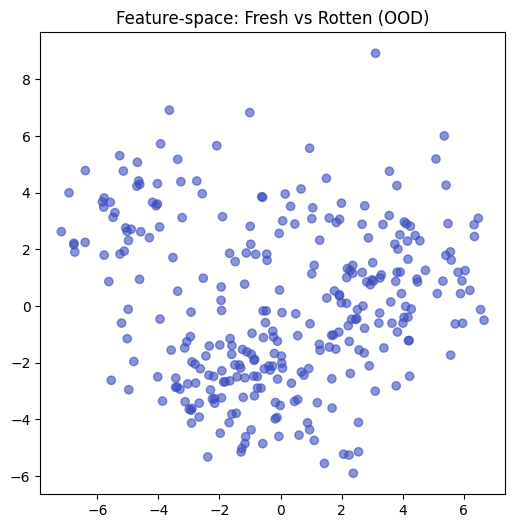

In [ ]:
X_sample, y_sample = load_binary_dataset("/content/kaggle_fruits", max_images=300)
features = extract_features(models["MobileNet_16_Finetuned"], X_sample)

pca = PCA(n_components=2)
Z = pca.fit_transform(features)

plt.figure(figsize=(6,6))
plt.scatter(Z[:,0], Z[:,1], c=y_sample, cmap='coolwarm', alpha=0.6)
plt.title("Feature-space: Fresh vs Rotten (OOD)")
plt.show()


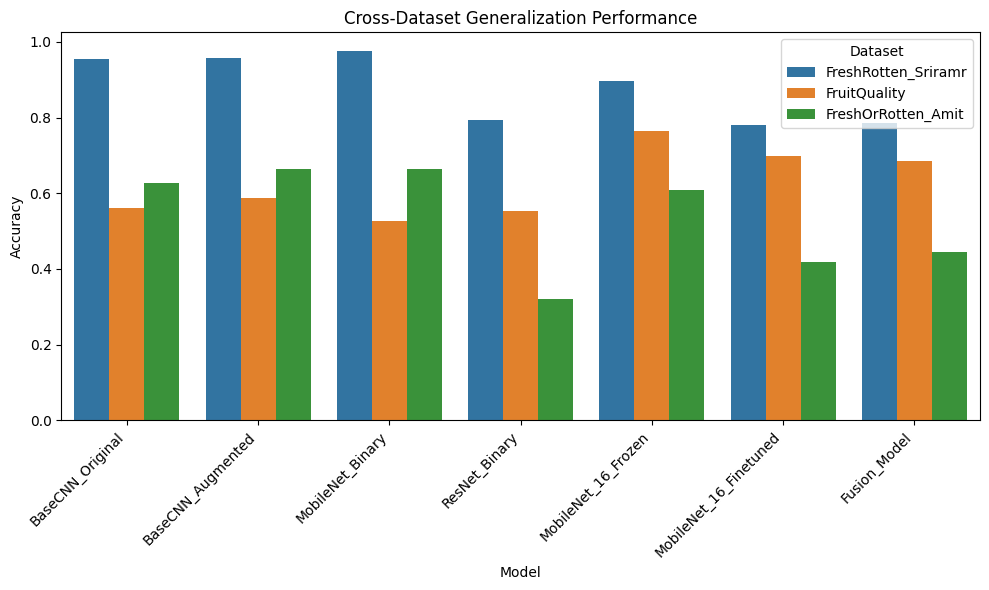

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# df_results must already exist
# columns: Dataset, Model, Accuracy

plt.figure(figsize=(10,6))
sns.barplot(
    data=df,
    x="Model",
    y="Accuracy",
    hue="Dataset"
)

plt.xticks(rotation=45, ha="right")
plt.title("Cross-Dataset Generalization Performance")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

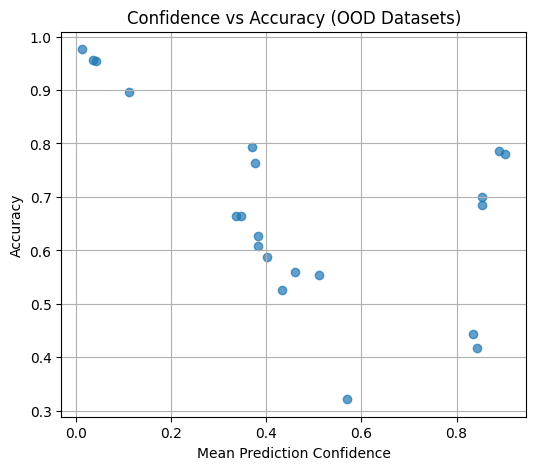

In [ ]:
import numpy as np

plt.figure(figsize=(6,5))
plt.scatter(df["ConfidenceMean"], df["Accuracy"], alpha=0.7)
plt.xlabel("Mean Prediction Confidence")
plt.ylabel("Accuracy")
plt.title("Confidence vs Accuracy (OOD Datasets)")
plt.grid(True)
plt.show()

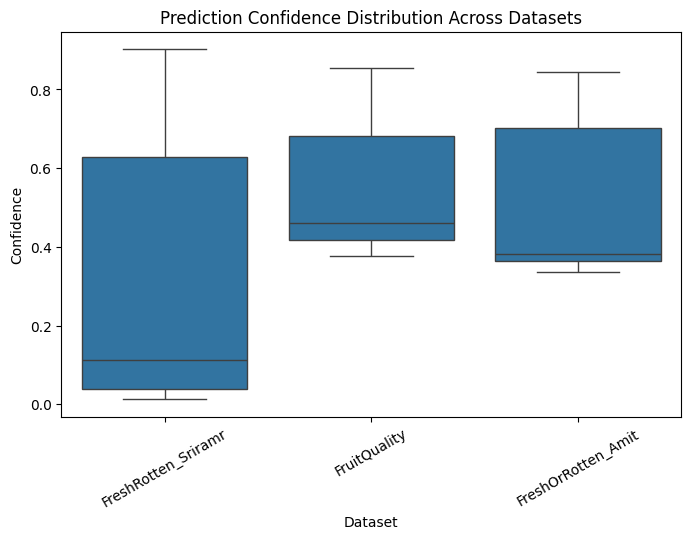

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x="Dataset",
    y="ConfidenceMean"
)
plt.title("Prediction Confidence Distribution Across Datasets")
plt.ylabel("Confidence")
plt.xticks(rotation=30)
plt.show()

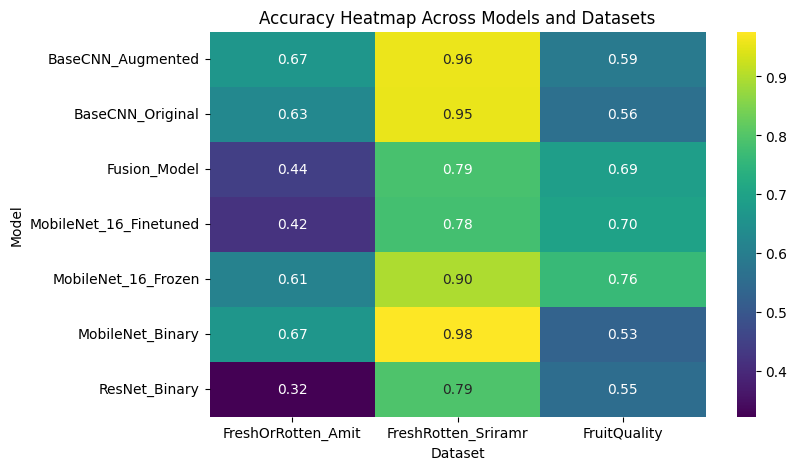

In [ ]:
pivot = df.pivot_table(
    index="Model",
    columns="Dataset",
    values="Accuracy"
)

plt.figure(figsize=(8,5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis")
plt.title("Accuracy Heatmap Across Models and Datasets")
plt.show()

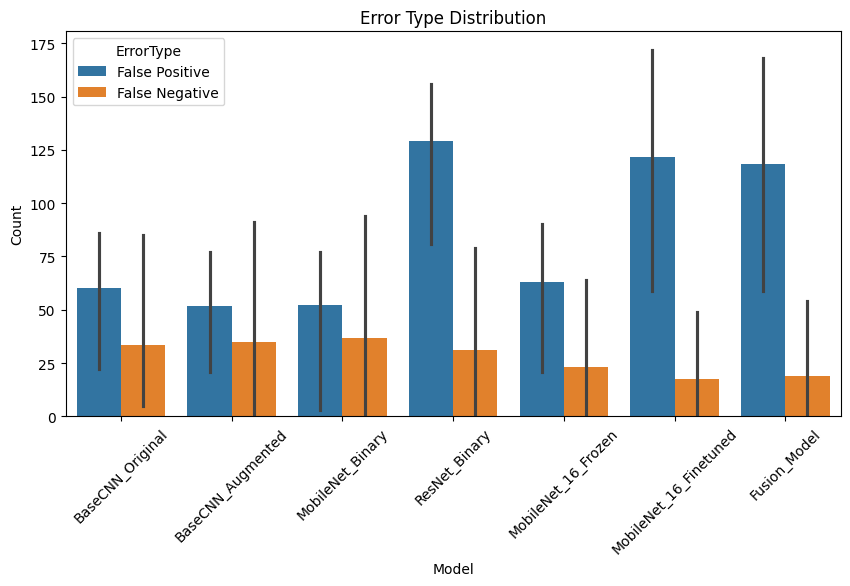

In [ ]:
error_data = []

for dname, dpath in DATASETS.items():
    # Re-load the dataset as X and y_true are overwritten in each iteration of the outer loop.
    # Using the same max_images=800 for consistency with previous evaluations.
    X_dataset, y_true_dataset = load_binary_dataset(dpath, max_images=800)

    if len(X_dataset) == 0:
        continue

    for mname, model in models.items():
        y_pred, _ = predict_binary(model, X_dataset)

        # Calculate error types: Fresh is 0, Rotten is 1
        false_positives = np.sum((y_true_dataset == 0) & (y_pred == 1))
        false_negatives = np.sum((y_true_dataset == 1) & (y_pred == 0))

        error_data.append([dname, mname, "False Positive", false_positives])
        error_data.append([dname, mname, "False Negative", false_negatives])

df_errors = pd.DataFrame(error_data, columns=["Dataset", "Model", "ErrorType", "Count"])

plt.figure(figsize=(10,5))
sns.barplot(
    data=df_errors,
    x="Model",
    y="Count",
    hue="ErrorType"
)
plt.xticks(rotation=45)
plt.title("Error Type Distribution")
plt.show()

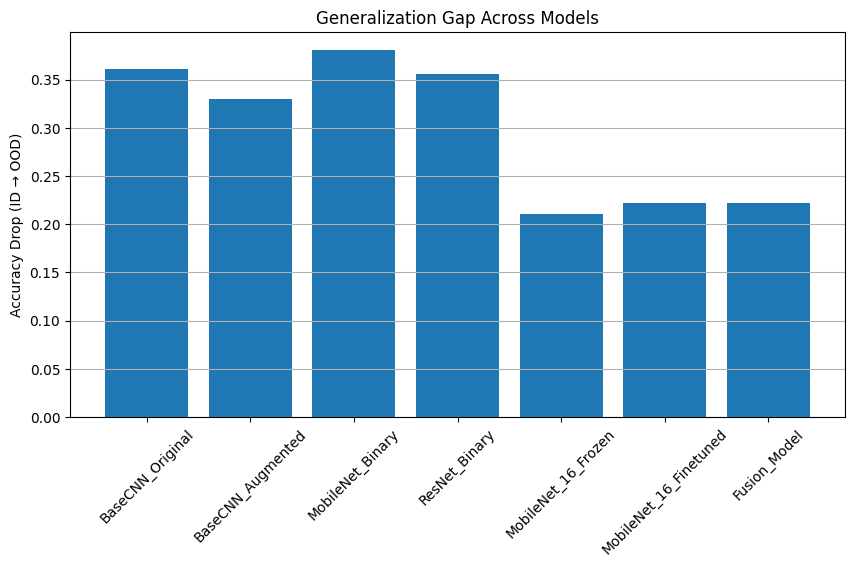

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# df should already contain: Dataset, Model, Accuracy
id_dataset = "FreshRotten_Sriramr"  # closest to training domain

gap_data = []

for model in df["Model"].unique():
    id_acc = df[(df["Dataset"] == id_dataset) & (df["Model"] == model)]["Accuracy"].values
    if len(id_acc) == 0:
        continue
    id_acc = id_acc[0]

    ood_acc = df[(df["Dataset"] != id_dataset) & (df["Model"] == model)]["Accuracy"].mean()
    gap_data.append([model, id_acc - ood_acc])

gap_df = pd.DataFrame(gap_data, columns=["Model", "Accuracy_Drop"])

plt.figure(figsize=(10,5))
plt.bar(gap_df["Model"], gap_df["Accuracy_Drop"])
plt.xticks(rotation=45)
plt.ylabel("Accuracy Drop (ID → OOD)")
plt.title("Generalization Gap Across Models")
plt.grid(axis="y")
plt.show()

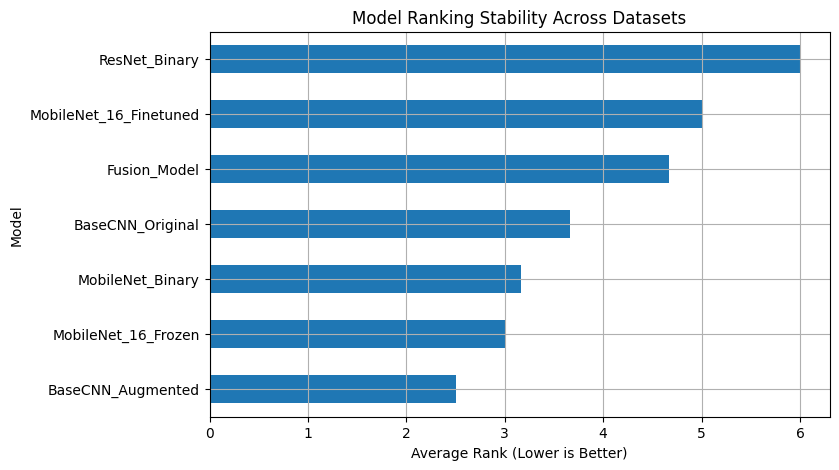

In [ ]:
rank_records = []

for dataset in df["Dataset"].unique():
    subset = df[df["Dataset"] == dataset].copy()
    subset["Rank"] = subset["Accuracy"].rank(ascending=False)
    rank_records.append(subset[["Model", "Rank"]])

rank_df = pd.concat(rank_records)
avg_rank = rank_df.groupby("Model")["Rank"].mean().sort_values()

plt.figure(figsize=(8,5))
avg_rank.plot(kind="barh")
plt.xlabel("Average Rank (Lower is Better)")
plt.title("Model Ranking Stability Across Datasets")
plt.grid()
plt.show()

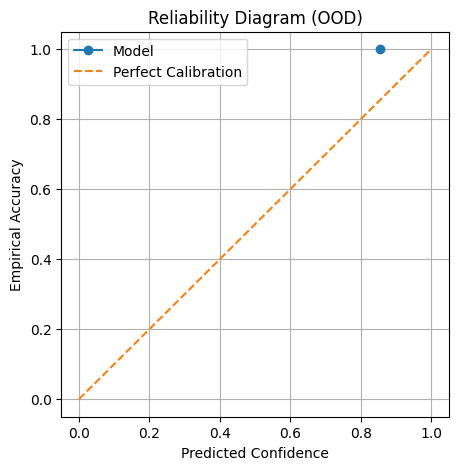

In [ ]:
import numpy as np

def reliability_curve(confidence, correct, n_bins=10):
    bins = np.linspace(0, 1, n_bins+1)
    acc_bin, conf_bin = [], []

    for i in range(n_bins):
        idx = (confidence >= bins[i]) & (confidence < bins[i+1])
        if idx.sum() == 0:
            continue
        acc_bin.append(correct[idx].mean())
        conf_bin.append(confidence[idx].mean())

    return conf_bin, acc_bin

# Example: use one dataset + one model
subset = df[(df["Dataset"]=="FruitQuality") & (df["Model"]=="Fusion_Model")]

confidence = subset["ConfidenceMean"].values
correct = subset["Accuracy"].values > 0.5  # proxy for correctness

conf_bin, acc_bin = reliability_curve(confidence, correct)

plt.figure(figsize=(5,5))
plt.plot(conf_bin, acc_bin, marker="o", label="Model")
plt.plot([0,1],[0,1],"--", label="Perfect Calibration")
plt.xlabel("Predicted Confidence")
plt.ylabel("Empirical Accuracy")
plt.title("Reliability Diagram (OOD)")
plt.legend()
plt.grid()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Example for a single model/dataset
dataset_name = "FruitQuality"
X_ood, y_ood = load_binary_dataset(DATASET_PATHS[dataset_name], max_images=800)
mname = "Fusion_Model"
y_pred, conf = predict_binary(models[mname], X_ood)

bins = np.linspace(0, 1, 6)  # e.g., 0.0–0.2, 0.2–0.4, ...
bin_indices = np.digitize(conf, bins) - 1

bin_acc = []
bin_centers = []
for i in range(len(bins)-1):
    mask = bin_indices == i


NameError: name 'load_binary_dataset' is not defined